# Quick start: LISST-VSF

This tutorial shows how to read raw LISST-VSF files, run the processing chain
and use its outputs: beam attenuation, volume scattering function (VSF) and
Mueller matrix terms, phase function and backscattering ratio, and export
to netCDF.

The example is a culture of the dinoflagellate *Lingulodinium polyedra*
(sample `LIN_S_C1_R1`) measured during the HABLAB experiment.

> **Note:** the data files used here are not distributed with the package. Set `datadir` to the location of your own files to run this notebook. In the documentation, the notebook is rendered with its saved outputs.

## Input files

A LISST-VSF processing requires two raw binary files:

- the **sample** measurement, `V<DDDHHMM>.VSF`;
- a **clean-water background** (blank) measurement, `Z<DDDHHMM>.VSF`,
  acquired with the same instrument settings (e.g. MilliQ water). It is used to
  remove the scattering of water and of the instrument optics, and as the
  reference for the beam attenuation.

The file names encode the day of year, hour and minute of the start of the acquisition.

In [1]:
import os
import warnings

import numpy as np
import matplotlib.pyplot as plt

from pylisst import driver, calib, process, utils, __version__

warnings.filterwarnings('ignore')
opj = os.path.join
print('pylisst', __version__)

pylisst 1.0.2


In [2]:
datadir = '/DATA/projet/gernez/hablab/lisst_vsf/raw/2022'

sample_file = opj(datadir, 'V1110854.VSF')  # LIN_S_C1_R1
blank_file = opj(datadir, 'Z1111704.VSF')   # MilliQ water

## Read the raw data

`driver` reads the binary file; `reader()` parses the records, subtracts the dark
signal (laser off) and interpolates the eyeball signals onto a common 1-degree
angular grid.

In [3]:
scat = driver(sample_file)
scat.reader()
zsc = driver(blank_file)
zsc.reader()

print('number of measurement sets: sample', scat.nsets, '| blank', zsc.nsets)

number of measurement sets: sample 50 | blank 100


Each measurement set holds two rotations of the eyeball detector: the first one with
the laser polarized perpendicular to the scattering plane, the second one with the laser
polarized parallel (via a half-wave plate). For each rotation, two photomultipliers
(`r` and `p`) record the scattered light, giving four signals:

| Signal | Laser polarization | Detector |
|--------|--------------------|----------|
| `rp`   | perpendicular      | `p`      |
| `rr`   | perpendicular      | `r`      |
| `pp`   | parallel           | `p`      |
| `pr`   | parallel           | `r`      |

They are {py:class}`xarray.DataArray` objects with dimensions `(set, angles)`:

In [4]:
scat.rp

<xarray.DataArray '' (set: 50, angles: 150)>
array([[ 36., 230., 961., ...,  95.,  80.,  53.],
       [ 40., 219., 894., ...,  92.,  82.,  58.],
       [ 37., 208., 900., ..., 101.,  76.,  58.],
       ...,
       [ 39., 219., 872., ...,  94.,  74.,  57.],
       [ 32., 179., 767., ...,  43.,  39.,  37.],
       [ 41., 226., 872., ...,  95.,  70.,  58.]])
Coordinates:
  * set      (set) int64 0 1 2 3 4 5 6 7 8 9 ... 40 41 42 43 44 45 46 47 48 49
  * angles   (angles) float64 5.0 6.0 7.0 8.0 9.0 ... 151.0 152.0 153.0 154.0
    pmt      (set) int64 435 435 435 435 435 435 435 ... 435 435 435 435 435 435
Attributes:
    description:  LISST-VSF
    units:        -

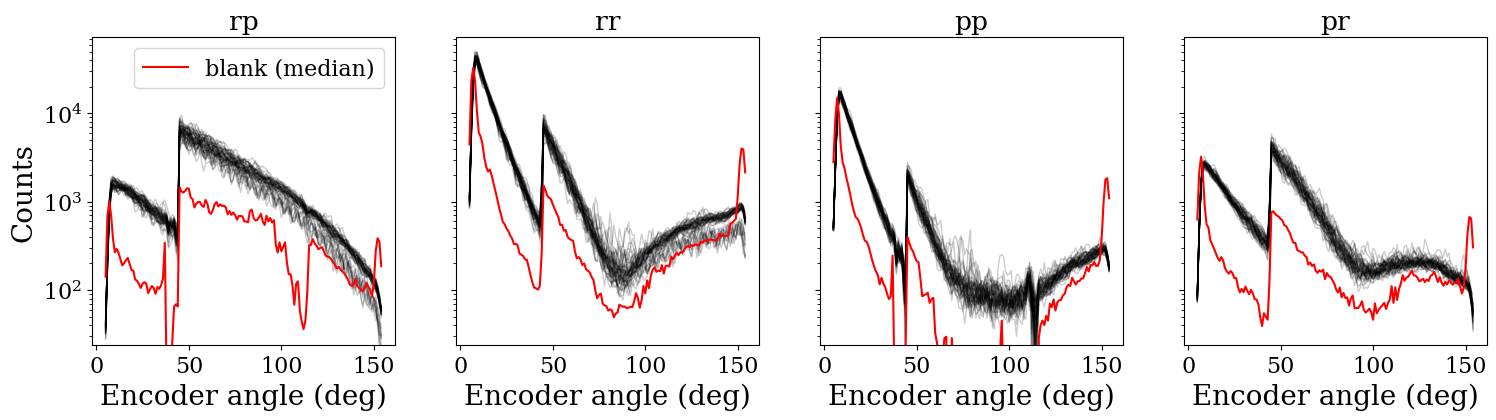

In [5]:
fig, axs = plt.subplots(ncols=4, figsize=(18, 4), sharey=True)
for ax, name in zip(axs, ['rp', 'rr', 'pp', 'pr']):
    getattr(scat, name).plot(hue='set', color='black', alpha=0.2, lw=1, add_legend=False, ax=ax)
    getattr(zsc, name).median('set').plot(color='red', lw=1.5, ax=ax, label='blank (median)')
    ax.set_title(name)
    ax.set_xlabel('Encoder angle (deg)')
axs[0].set_ylabel('Counts')
axs[0].semilogy()
axs[0].legend()
plt.show()

## Run the processing chain

`process` combines the sample, the blank and the calibration factors of the instrument
(`calib`). `full_process()` runs the whole chain (see {doc}`../processing_chain`).

In [6]:
p = process(scat, zsc, calib())
p.full_process()

Main outputs:

| Attribute  | Description                                                   | Dimensions        |
|------------|---------------------------------------------------------------|-------------------|
| `beam_c`   | Beam attenuation coefficient (m$^{-1}$), for each rotation    | `(set, config)`   |
| `ring_vsf` | VSF from the ring detectors (m$^{-1}$ sr$^{-1}$)              | `(set, angles)`   |
| `p11`      | VSF from the eyeball, scaled onto the rings                   | `(set, angles)`   |
| `p12`      | $P_{12}/P_{11}$ (degree of linear polarization, with sign)    | `(set, angles)`   |
| `p22`      | $P_{22}/P_{11}$                                               | `(set, angles)`   |
| `P11`      | VSF merged from rings and eyeball over the full angular range | `(set, angles)`   |
| `alpha`    | Relative gain of the two eyeball photomultipliers             | scalar            |

Angles are scattering angles in water, in degrees.

In [7]:
print('P11 angular range: {:.2f} - {:.1f} deg'.format(float(p.P11.angles.min()), float(p.P11.angles.max())))
print('PMT relative gain alpha: {:.3f}'.format(p.alpha))
p.P11

P11 angular range: 0.09 - 154.0 deg
PMT relative gain alpha: 0.747


<xarray.DataArray (set: 50, angles: 173)>
array([[1.80653380e+04, 1.56927330e+04, 1.75376613e+04, ...,
        7.76168276e-03, 8.97801911e-03, 7.62356762e-03],
       [1.97917006e+04, 1.71600331e+04, 1.74406884e+04, ...,
        7.25955914e-03, 7.06145176e-03, 6.17844538e-03],
       [1.72813591e+04, 1.62157526e+04, 1.67459519e+04, ...,
        6.30670970e-03, 6.45689507e-03, 6.21030219e-03],
       ...,
       [1.78833208e+04, 1.64904667e+04, 1.81254031e+04, ...,
        7.21339626e-03, 7.05793979e-03, 6.79361250e-03],
       [1.42484601e+04, 1.93238219e+04, 1.82164737e+04, ...,
        4.90373722e-03, 5.23734537e-03, 4.39345462e-03],
       [1.70335133e+04, 1.52195482e+04, 1.71504240e+04, ...,
        7.53324718e-03, 7.47173922e-03, 6.84863634e-03]])
Coordinates:
  * set      (set) int64 0 1 2 3 4 5 6 7 8 9 ... 40 41 42 43 44 45 46 47 48 49
    pmt      (set) int64 435 435 435 435 435 435 435 ... 435 435 435 435 435 435
  * angles   (angles) float64 0.08803 0.1039 0.1226 0.1447 ... 152.0 153.0 154.0

### Beam attenuation

`config=0` and `config=1` correspond to the perpendicular and parallel rotations.

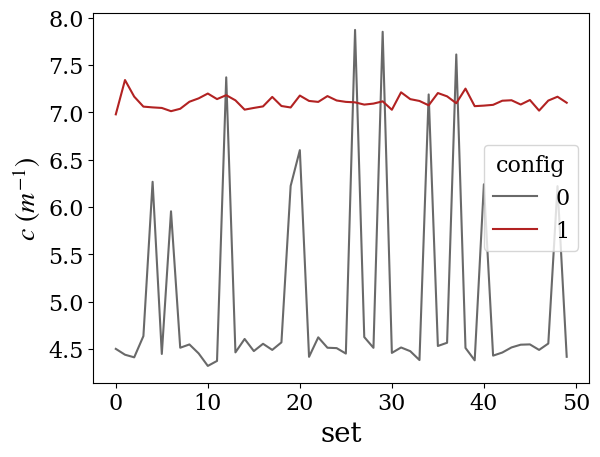

median c = 7.034 m-1


In [8]:
p.beam_c.plot(hue='config')
plt.ylabel('$c\\ (m^{-1})$')
plt.show()
print('median c = {:.3f} m-1'.format(float(p.beam_c.median())))

### VSF and Mueller matrix terms

`utils.plot().semilog` splits an axis into a logarithmic part (near-forward angles,
ring detectors) and a linear part (large angles, eyeball). The vertical line marks the change of scale (5 degrees).

$P_{22}$ is masked within 40-50 and 130-140 degrees, where its retrieval is corrupted
(see {py:meth}`~pylisst.process.process.get_matrix_terms`).

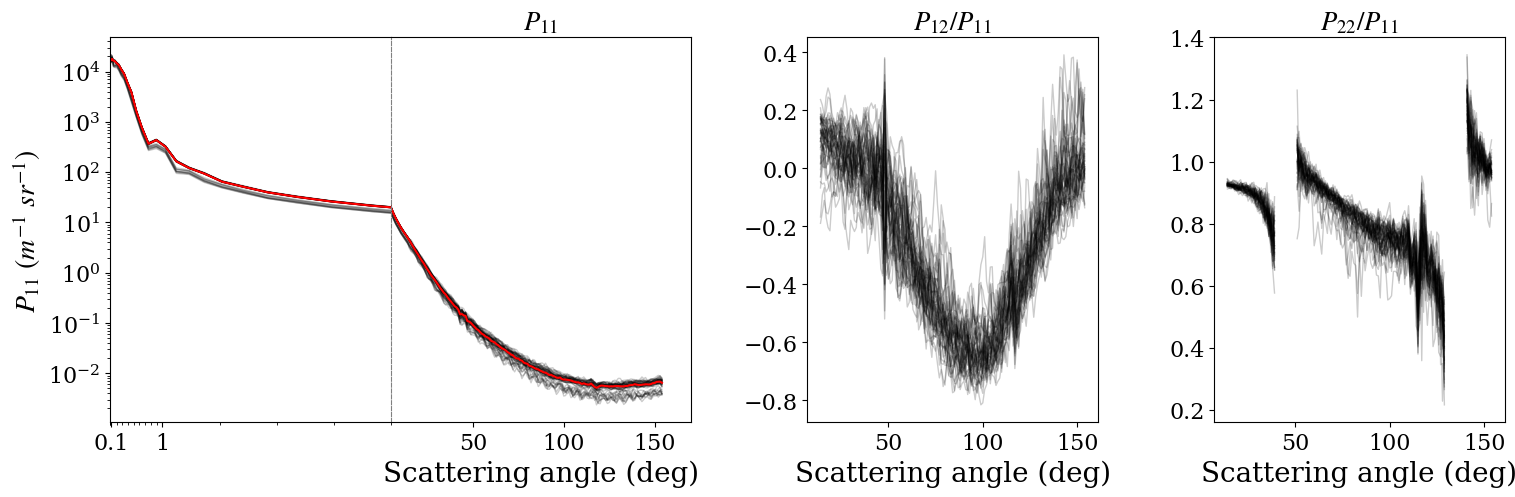

In [9]:
fig, axs = plt.subplots(ncols=3, figsize=(18, 5), gridspec_kw={'width_ratios': [2, 1, 1]})
fig.subplots_adjust(wspace=0.3)

ax, axlin = utils.plot().semilog(axs[0], size=3)
for ax_ in (ax, axlin):
    p.P11.plot(hue='set', color='black', alpha=0.2, lw=1, add_legend=False, ax=ax_)
    p.P11.median('set').plot(color='red', lw=1.5, ax=ax_)
ax.set_ylabel('$P_{11}\\ (m^{-1}\\ sr^{-1})$')
ax.set_xticks([0.1, 1], ['0.1', '1'])
ax.set_xlabel('')
ax.set_title('')
axlin.set_title('$P_{11}$')
axlin.xaxis.set_visible(True)
axlin.set_xlabel('Scattering angle (deg)')

p.p12.plot(hue='set', color='black', alpha=0.2, lw=1, add_legend=False, ax=axs[1])
p.p22.plot(hue='set', color='black', alpha=0.2, lw=1, add_legend=False, ax=axs[2])
for ax_, title in zip(axs[1:], ['$P_{12}/P_{11}$', '$P_{22}/P_{11}$']):
    ax_.set_title(title)
    ax_.set_xlabel('Scattering angle (deg)')
    ax_.set_ylabel('')
plt.show()

## Step-by-step processing

`full_process()` is equivalent to the sequence below. Running the steps one by one
allows to inspect intermediate results or to modify a step, e.g. to provide the
photomultiplier relative gain `alpha` instead of estimating it from the data, or
to change the geometric correction `geom_corr` (see {doc}`beads_process`).

Note that the processing modifies the `driver` objects in place: read the files
again before processing them a second time.

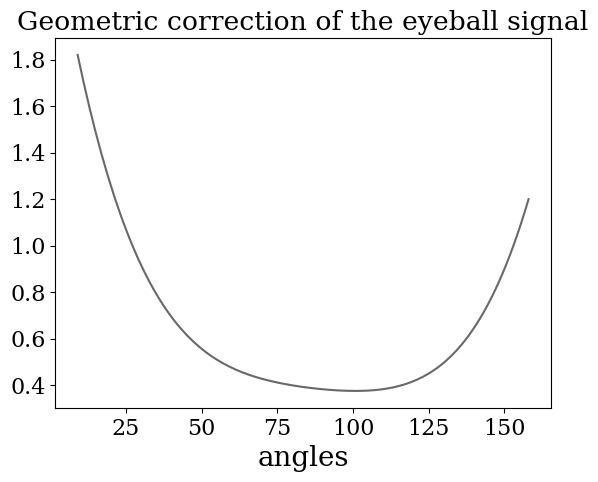

In [10]:
scat = driver(sample_file)
scat.reader()
zsc = driver(blank_file)
zsc.reader()

p2 = process(scat, zsc, calib(), alpha=p.alpha)
p2.auxdata()                 # depth, temperature, battery in physical units
p2.get_attenuation()         # transmittance and beam attenuation
p2.get_angles()              # encoder index -> scattering angle
p2.get_scattering_volume()   # geometric correction of the eyeball
p2.process_large_angles()    # eyeball signals corrected for background, attenuation, geometry
p2.process_forward_angles()  # ring detectors -> near-forward VSF
p2.get_matrix_terms()        # p11, p12, p22 from the eyeball signals
p2.merge_angles()            # rings + eyeball -> P11
p2.apply_QC(drop=False)      # quality control (see below)

p2.geom_corr.plot()
plt.title('Geometric correction of the eyeball signal')
plt.show()

## Quality control

`apply_QC` (run by `full_process(quality_control=True)`, the default) masks the angles
where less than half of the sets are valid (`QC_count`) or where the coefficient of
variation between sets exceeds 0.5 (`QC_CV`). With `drop=True`, these angles are removed
instead of being set to NaN. The thresholds can be changed by calling the methods directly:

In [11]:
strict = p2.QC_CV(thresh=0.2, drop=False)
print('valid angles: default QC', int(p2.P11.median('set').notnull().sum()),
      '| CV < 0.2:', int(strict.median('set').notnull().sum()))

valid angles: default QC 173 | CV < 0.2: 125


Auxiliary data are available per set and per rotation:

In [12]:
print('time:', p.timestamp[0, 0], '->', p.timestamp[-1, -1])
print('temperature: {:.2f} degC'.format(np.median(p.tempC)))

time: 2022-04-21T08:54:28.000000 -> 2022-04-21T08:57:15.000000
temperature: 21.71 degC


## Phase function and backscattering ratio

The scattering coefficient $b$ and the backscattering coefficient $b_b$ are obtained by
integrating the VSF:

$$b = 2\pi \int_0^{\pi} \beta(\theta) \sin\theta \, d\theta, \qquad
b_b = 2\pi \int_{\pi/2}^{\pi} \beta(\theta) \sin\theta \, d\theta$$

and the phase function is $\tilde{\beta} = \beta / b$. Here the integrals are limited to the
measured angular range (about 0.09-154 degrees), so $b$ and $b_b$ are underestimated:
the missing angles can be accounted for by fitting an analytical phase function
(see {doc}`post_processing`).

b (measured range) = 6.641 m-1
bb/b (measured range) = 0.0056


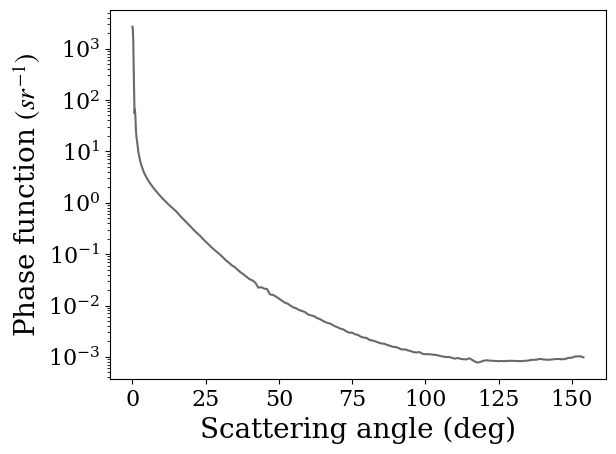

In [13]:
vsf = p.P11.median('set').dropna('angles')
theta = np.radians(vsf.angles.values)
integrand = vsf.values * np.sin(theta)
back = vsf.angles.values >= 90

b = 2 * np.pi * np.trapz(integrand, theta)
bb = 2 * np.pi * np.trapz(integrand[back], theta[back])
print('b (measured range) = {:.3f} m-1'.format(b))
print('bb/b (measured range) = {:.4f}'.format(bb / b))

phase_function = vsf / b
phase_function.plot()
plt.semilogy()
plt.ylabel('Phase function $(sr^{-1})$')
plt.xlabel('Scattering angle (deg)')
plt.show()

## Export to netCDF

The outputs can be gathered into an {py:class}`xarray.Dataset` and saved as netCDF, as
done for the Level-2 files of the HABLAB experiment (see {doc}`hablab_process`).

In [14]:
import xarray as xr

output = xr.Dataset({'beam_c': p.beam_c,
                     'P11': p.P11,
                     'p12': p.p12,
                     'p22': p.p22})
output.attrs = {'sample': 'LIN_S_C1_R1',
                'sample_file': os.path.basename(sample_file),
                'blank_file': os.path.basename(blank_file),
                'pylisst_version': __version__}
# output.to_netcdf('LIN_S_C1_R1_scat_mat.nc')
output

<xarray.Dataset>
Dimensions:  (set: 50, config: 2, angles: 173)
Coordinates:
  * set      (set) int64 0 1 2 3 4 5 6 7 8 9 ... 40 41 42 43 44 45 46 47 48 49
  * config   (config) int64 0 1
    pmt      (set) int64 435 435 435 435 435 435 435 ... 435 435 435 435 435 435
  * angles   (angles) float64 0.08803 0.1039 0.1226 0.1447 ... 152.0 153.0 154.0
Data variables:
    beam_c   (set, config) float64 4.501 6.98 4.439 7.342 ... 7.166 4.417 7.102
    P11      (set, angles) float64 1.807e+04 1.569e+04 ... 0.007472 0.006849
    p12      (set, angles) float64 nan nan nan nan ... -0.01591 0.01849 0.005148
    p22      (set, angles) float64 nan nan nan nan ... 0.9952 0.9909 0.9694
Attributes:
    sample:           LIN_S_C1_R1
    sample_file:      V1110854.VSF
    blank_file:       Z1111704.VSF
    pylisst_version:  1.0.2